In [ ]:
# Cell 1 — 首次執行安裝
%pip install torch torchvision pandas scikit-learn pillow matplotlib tqdm nltk google-genai pydantic

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# Cell 2 — 設定、讀取 Flickr30k 與依圖片切分
import os
import re
import random
import json
from collections import Counter
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
import matplotlib.pyplot as plt

IMAGE_DIR = "../Data/flickr30k_images"
CSV_PATH = "../Data/results.csv"
SEED = 12
BATCH_SIZE = 32             
MAX_LENGTH = 40           
MIN_FREQ = 2
EMBED_DIM = 256
HIDDEN_DIM = 512
NUM_LAYERS = 1
NUM_EPOCH = 50
LR_ENCODER = 1e-5
LR_DECODER = 1e-3
UNFREEZE_ENCODER_LAYER4 = True   # 微調 ResNet-18 最後一個 residual block
NUM_WORKERS = 2                 # Windows / Jupyter 比較穩定
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_all(SEED)

# Flickr30k results.csv 通常為 image_name| comment_number| comment
df = pd.read_csv(CSV_PATH, sep='|', encoding='utf-8-sig')
df.columns = df.columns.str.strip()
assert {'image_name', 'comment'}.issubset(df.columns), f'CSV columns: {df.columns.tolist()}'
df['image_name'] = df['image_name'].astype('string').str.strip()
df['comment'] = df['comment'].astype('string').str.strip()
df = df.dropna(subset=['image_name', 'comment'])
df = df[(df['image_name'] != '') & (df['comment'] != '')].copy()
df = df[df['image_name'].map(lambda x: os.path.isfile(os.path.join(IMAGE_DIR, x)))].reset_index(drop=True)

unique_images = df['image_name'].unique()
train_images, temp_images = train_test_split(unique_images, test_size=0.2, random_state=SEED, shuffle=True)
val_images, test_images = train_test_split(temp_images, test_size=0.5, random_state=SEED, shuffle=True)
assert set(train_images).isdisjoint(val_images)
assert set(train_images).isdisjoint(test_images)
assert set(val_images).isdisjoint(test_images)
train_df = df[df.image_name.isin(train_images)].reset_index(drop=True)
val_df = df[df.image_name.isin(val_images)].reset_index(drop=True)
test_df = df[df.image_name.isin(test_images)].reset_index(drop=True)
print('Device:', DEVICE)
print('Train / Val / Test images:', len(train_images), len(val_images), len(test_images))
print('Caption rows:', len(train_df), len(val_df), len(test_df))

Device: cuda
Train / Val / Test images: 25426 3178 3179
Caption rows: 127129 15890 15895


In [16]:
# Cell 3 — Vocabulary（僅從 train_df 建立，避免 test 資訊洩漏）
SPECIAL_TOKENS = ['<pad>', '<bos>', '<eos>', '<unk>']
def tokenize(text):
    # 基礎英文 tokenization；訓練、BLEU、生成均共用
    return re.findall(r"[a-z0-9]+|[^\w\s]", str(text).lower())

counter = Counter(tok for cap in train_df['comment'] for tok in tokenize(cap))
itos = SPECIAL_TOKENS + sorted(w for w, freq in counter.items() if freq >= MIN_FREQ and w not in SPECIAL_TOKENS)
stoi = {w: i for i, w in enumerate(itos)}
PAD_ID, BOS_ID, EOS_ID, UNK_ID = (stoi[s] for s in SPECIAL_TOKENS)

def encode_caption(text, max_length=MAX_LENGTH):
    ids = [BOS_ID] + [stoi.get(tok, UNK_ID) for tok in tokenize(text)[:max_length-2]] + [EOS_ID]
    ids += [PAD_ID] * (max_length - len(ids))
    return torch.tensor(ids, dtype=torch.long)

def decode_caption(ids):
    words = []
    for idx in ids:
        idx = int(idx)
        if idx == EOS_ID:
            break
        if idx not in (PAD_ID, BOS_ID):
            words.append(itos[idx])
    return ' '.join(words)

print('Vocabulary size:', len(itos))
print('Example:', decode_caption(encode_caption(train_df.iloc[0]['comment'])))

Vocabulary size: 11105
Example: several men in hard hats are operating a giant pulley system .


In [17]:
# Cell 4 — 快速 Dataset/DataLoader：每張圖片每 epoch 隨機選 1 個 caption
# Windows + Jupyter：先用 0 workers，避免多程序啟動／序列化卡住
import os
import random
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

BATCH_SIZE = 128
NUM_WORKERS = 0

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class Flickr30kDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform, random_caption=False):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform
        self.random_caption = random_caption
        # 同一張圖片合併成一筆；每張圖保留全部 captions
        self.samples = [
            (name, group['comment'].astype(str).tolist())
            for name, group in self.df.groupby('image_name', sort=False)
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        filename, captions = self.samples[idx]
        caption = random.choice(captions) if self.random_caption else captions[0]
        with Image.open(os.path.join(self.image_dir, filename)) as im:
            pixel_values = self.transform(im.convert('RGB'))
        return {
            'pixel_values': pixel_values,
            'caption_ids': encode_caption(caption),
        }

train_dataset = Flickr30kDataset(train_df, IMAGE_DIR, train_transform, random_caption=True)
val_dataset = Flickr30kDataset(val_df, IMAGE_DIR, eval_transform)
test_dataset = Flickr30kDataset(test_df, IMAGE_DIR, eval_transform)

loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == 'cuda'),
    persistent_workers=(NUM_WORKERS > 0),
)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)
# 已經是一圖一筆，可直接用於 BLEU；保留既有變數名稱
val_unique_df = val_df.drop_duplicates('image_name').reset_index(drop=True)
test_unique_df = test_df.drop_duplicates('image_name').reset_index(drop=True)
val_unique_loader = val_loader
test_unique_loader = test_loader

print('Batch size:', train_loader.batch_size)
print('Workers:', train_loader.num_workers)
print('Unique train/val/test images:', len(train_dataset), len(val_dataset), len(test_dataset))
print('Training caption sampling: 1 random reference per image per epoch')

Batch size: 128
Workers: 0
Unique train/val/test images: 25426 3178 3179
Training caption sampling: 1 random reference per image per epoch


In [18]:
# Cell 5 — ResNet-18 Encoder + LSTM Decoder
class ResNet18LSTMCaptioner(nn.Module):
    def __init__(self, vocab_size, embed_dim=256, hidden_dim=512, num_layers=1,
                 fine_tune_layer4=True, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        self.encoder = models.resnet18(weights=weights)
        cnn_dim = self.encoder.fc.in_features  # 512
        self.encoder.fc = nn.Identity()         # [B, 512]
        # ImageNet pretrained backbone; only layer4 is fine-tuned
        for p in self.encoder.parameters():
            p.requires_grad = False
        if fine_tune_layer4:
            for p in self.encoder.layer4.parameters():
                p.requires_grad = True
        self.image_projection = nn.Linear(cnn_dim, embed_dim)
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers=num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def encode_images(self, images):
        # layer4 微調時允許 Encoder 的 gradient，凍結的部分不更新權重
        if not any(p.requires_grad for p in self.encoder.parameters()):
            with torch.no_grad():
                features = self.encoder(images)
        else:
            # 凍結的 BatchNorm 以 eval 統計量推論，避免 batch 很小使 running stats 漂移
            self.encoder.eval()
            features = self.encoder(images)
        return self.image_projection(features)

    def forward(self, pixel_values, caption_ids):
        # 輸入 [IMG, BOS, w1, ... w(n-1)]，目標 [BOS, w1, ..., EOS]
        # 正確做法：IMG 用來預測 BOS，訓練時不評分此位置
        features = self.encode_images(pixel_values).unsqueeze(1)
        embeddings = self.embedding(caption_ids[:, :-1])
        lstm_input = torch.cat([features, embeddings], dim=1)
        lstm_output, _ = self.lstm(lstm_input)
        logits = self.fc(lstm_output[:, 1:, :])  # [B, T-1, V] 對齊 caption_ids[:, 1:]
        return logits

    @torch.no_grad()
    def generate(self, pixel_values, max_length=40):
        self.eval()
        batch_size = pixel_values.size(0)
        features = self.encode_images(pixel_values).unsqueeze(1)
        _, state = self.lstm(features)           # 圖片先進入 LSTM
        current = torch.full((batch_size, 1), BOS_ID, dtype=torch.long, device=pixel_values.device)
        outputs = []
        finished = torch.zeros(batch_size, dtype=torch.bool, device=pixel_values.device)
        for _ in range(max_length - 1):
            emb = self.embedding(current)
            h, state = self.lstm(emb, state)
            current = self.fc(h[:, -1]).argmax(dim=-1, keepdim=True)
            outputs.append(current)
            finished |= (current.squeeze(1) == EOS_ID)
            if finished.all():
                break
        return torch.cat(outputs, dim=1)

model = ResNet18LSTMCaptioner(
    vocab_size=len(itos), embed_dim=EMBED_DIM, hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS, fine_tune_layer4=UNFREEZE_ENCODER_LAYER4,
    pretrained=True
).to(DEVICE)
print('Total parameters:', f'{sum(p.numel() for p in model.parameters()):,}')
print('Trainable parameters:', f'{sum(p.numel() for p in model.parameters() if p.requires_grad):,}')

Total parameters: 21,424,545
Trainable parameters: 18,641,761


In [19]:
# Cell 6 — Train/Validation：CrossEntropy + tqdm + AMP
import time
criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
optimizer = torch.optim.AdamW([
    {'params': [p for p in model.encoder.parameters() if p.requires_grad], 'lr': LR_ENCODER},
    {'params': list(model.image_projection.parameters()) + list(model.embedding.parameters()) +
               list(model.lstm.parameters()) + list(model.fc.parameters()), 'lr': LR_DECODER}
], weight_decay=1e-4)
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE.type == 'cuda'))

def run_epoch(model, dataloader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    model.encoder.eval()    # 避免預訓練 BN running statistics 漂移
    loss_total, token_count = 0.0, 0
    bar = tqdm(dataloader, desc='Train' if training else 'Validation', leave=True)
    for batch in bar:
        images = batch['pixel_values'].to(DEVICE, non_blocking=True)
        caption_ids = batch['caption_ids'].to(DEVICE, non_blocking=True)
        targets = caption_ids[:, 1:]
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == 'cuda')):
                logits = model(images, caption_ids)
                loss = criterion(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
        tokens = (targets != PAD_ID).sum().item()
        loss_total += loss.item() * tokens
        token_count += tokens
        bar.set_postfix(loss=f'{loss.item():.3f}')
    return loss_total / max(token_count, 1)

def calculate_bleu4(model, unique_loader, references_df):
    ref_map = references_df.groupby('image_name')['comment'].apply(list).to_dict()
    # 新 Dataset 每個 unique image 一筆
    unique_names = [name for name, _ in unique_loader.dataset.samples]
    refs, hyps = [], []
    k = 0
    model.eval()
    for batch in tqdm(unique_loader, desc='BLEU-4', leave=True):
        images = batch['pixel_values'].to(DEVICE, non_blocking=True)
        generated = model.generate(images, max_length=MAX_LENGTH).cpu().tolist()
        for ids in generated:
            name = unique_names[k]
            hyps.append(tokenize(decode_caption(ids)))
            refs.append([tokenize(x) for x in ref_map[name]])
            k += 1
    return corpus_bleu(refs, hyps, smoothing_function=SmoothingFunction().method1)

In [20]:
# Cell 7 — 快速 10 Epoch；BLEU 僅訓練結束後計算一次
import time
train_losses, val_losses = [], []
bleu_scores = []  # BLEU 最後算一次，不再每個 epoch 生成所有 caption
best_val_loss = float('inf')
CKPT_PATH = 'best_resnet18_lstm_caption.pth'

for epoch in range(NUM_EPOCH):
    start = time.perf_counter()
    print(f'\nEpoch {epoch+1}/{NUM_EPOCH}')
    train_loss = run_epoch(model, train_loader, optimizer=optimizer)
    train_time = time.perf_counter() - start
    val_start = time.perf_counter()
    val_loss = run_epoch(model, val_loader)
    val_time = time.perf_counter() - val_start
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            'model_state_dict': model.state_dict(), 'itos': itos,
            'embed_dim': EMBED_DIM, 'hidden_dim': HIDDEN_DIM,
            'num_layers': NUM_LAYERS, 'fine_tune_layer4': UNFREEZE_ENCODER_LAYER4,
            'max_length': MAX_LENGTH, 'epoch': epoch + 1,
            'best_val_loss': best_val_loss,
        }, CKPT_PATH)
    print(f'Epoch {epoch+1:02d}/{NUM_EPOCH} | Train {train_loss:.4f} | '
          f'Val {val_loss:.4f} | Train {train_time:.1f}s | Val {val_time:.1f}s')

checkpoint = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
bleu = calculate_bleu4(model, val_unique_loader, val_df)
bleu_scores.append(bleu)
print(f'Best epoch: {checkpoint["epoch"]} | Validation BLEU-4: {bleu:.4f}')
print('Checkpoint:', CKPT_PATH)


Epoch 1/50


Validation: 100%|██████████| 25/25 [00:12<00:00,  1.97it/s, loss=4.095]


Epoch 01/50 | Train 4.5098 | Val 4.0513 | Train 106.7s | Val 12.7s

Epoch 2/50


Validation: 100%|██████████| 25/25 [00:12<00:00,  2.08it/s, loss=3.821]


Epoch 02/50 | Train 3.7095 | Val 3.7704 | Train 100.5s | Val 12.0s

Epoch 3/50


...

Epoch 49/50 | Train 1.8756 | Val 3.2757 | Train 127.5s | Val 15.3s

Epoch 50/50


Validation: 100%|██████████| 25/25 [00:13<00:00,  1.91it/s, loss=3.302]


Epoch 50/50 | Train 1.8599 | Val 3.2855 | Train 125.0s | Val 13.1s


BLEU-4: 100%|██████████| 25/25 [00:13<00:00,  1.84it/s]


Best epoch: 23 | Validation BLEU-4: 0.1640
Checkpoint: best_resnet18_lstm_caption.pth


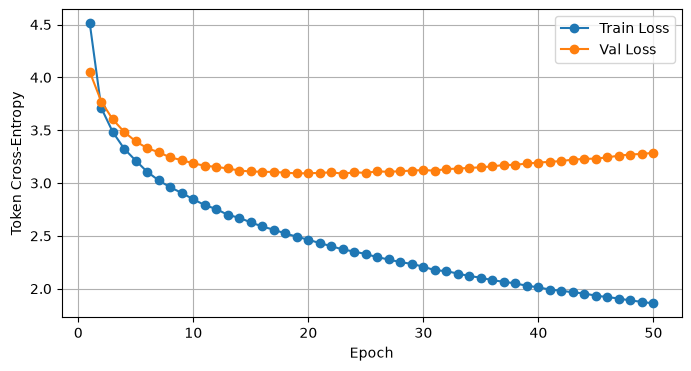

Best model Validation BLEU-4: 0.1640


In [21]:
# Cell 8 — Loss 曲線；BLEU 僅有最後的最佳模型評估值
xs = range(1, len(train_losses) + 1)
plt.figure(figsize=(8, 4))
plt.plot(xs, train_losses, marker='o', label='Train Loss')
plt.plot(xs, val_losses, marker='o', label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Token Cross-Entropy')
plt.legend()
plt.grid(True)
plt.show()
if bleu_scores:
    print(f'Best model Validation BLEU-4: {bleu_scores[-1]:.4f}')

In [22]:
# Cell 9 — 還原最佳模型 + Test BLEU-4
checkpoint = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=True)
assert checkpoint['itos'] == itos, '目前 Vocabulary 與 checkpoint 不一致。請先執行相同 train split / Vocabulary Cells。'
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
test_bleu = calculate_bleu4(model, test_unique_loader, test_df)
print(f'Test BLEU-4: {test_bleu:.4f}')

# 將每張測試圖片的預測輸出 CSV；不需要 Gemini / 網路
predictions = []
names = test_unique_df['image_name'].tolist()
idx = 0
with torch.inference_mode():
    for batch in tqdm(test_unique_loader, desc='Generate test captions'):
        generated = model.generate(batch['pixel_values'].to(DEVICE), MAX_LENGTH).cpu().tolist()
        for ids in generated:
            predictions.append({'image_name': names[idx], 'generated_caption': decode_caption(ids)})
            idx += 1
predictions_df = pd.DataFrame(predictions)
predictions_df.to_csv('resnet18_lstm_test_captions.csv', index=False, encoding='utf-8-sig')
display(predictions_df.head(10))

BLEU-4: 100%|██████████| 25/25 [00:14<00:00,  1.76it/s]


Test BLEU-4: 0.1648


Generate test captions: 100%|██████████| 25/25 [00:13<00:00,  1.87it/s]


,image_name,generated_caption
0,1000092795.jpg,a young woman in a blue shirt and jeans is wal...
1,1000268201.jpg,a woman in a blue shirt is sitting at a table ...
2,10010052.jpg,a young woman in a blue shirt is walking down ...
3,1001465944.jpg,a man and a woman are walking in front of a la...
4,100207720.jpg,a man in a blue shirt is playing a game with a...
5,1009692167.jpg,a man in a black jacket is riding a motorcycle .
6,1017675163.jpg,a gymnast is performing a jump in front of a c...
7,1022454332.jpg,a man and a woman are walking along a river .
8,102351840.jpg,two women in winter coats walking down a road .
9,102860573.jpg,a man in a blue shirt is sitting at a table wi...


In [25]:
# Cell 10 — Gemini API Key：隱藏輸入、不寫入 Notebook
from google import genai
from getpass import getpass
from pydantic import BaseModel, Field

client = genai.Client(api_key=getpass('Gemini API Key: '))

class CaptionEvaluation(BaseModel):
    score: int = Field(ge=0, le=100)
    correct: bool
    reason: str

def judge_caption(image, caption):
    prompt = (
        'Evaluate this generated image caption against the attached image. '
        'Check factual objects, actions, relationships and hallucinations. '
        'Accept alternative correct wording and minor omitted details. '
        f'Caption: {caption!r}. '
        'Return score from 0 to 100; correct=true exactly when score>=70; '
        'give a concise explanation.'
    )
    res = client.models.generate_content(
        model='gemini-3.8-flash',
        contents=[prompt, image],
        config={'response_mime_type': 'application/json', 'response_schema': CaptionEvaluation}
    )
    if res.parsed is not None:
        return res.parsed
    return CaptionEvaluation.model_validate_json(res.text)

In [26]:
# Cell 11 — 使用最佳模型的 Test Caption，送給 Gemini 評估（每張圖片一次）
NUM_GEMINI_TEST = 20  # Gemini API 可能有費用及速率限制
results = []
for row in tqdm(predictions_df.head(NUM_GEMINI_TEST).itertuples(index=False),
                total=min(NUM_GEMINI_TEST, len(predictions_df)), desc='Gemini judge'):
    try:
        with Image.open(os.path.join(IMAGE_DIR, row.image_name)) as im:
            image = im.convert('RGB').copy()
        judge = judge_caption(image, row.generated_caption)
        results.append({'image_name': row.image_name,
                        'generated_caption': row.generated_caption,
                        'gemini_score': judge.score,
                        'correct': judge.correct,
                        'reason': judge.reason})
    except Exception as exc:
        print(f'Gemini failed on {row.image_name}: {exc}')

results_df = pd.DataFrame(results)
results_df.to_csv('resnet18_lstm_gemini_results.csv', index=False, encoding='utf-8-sig')
if len(results_df):
    print('Gemini average score:', round(results_df.gemini_score.mean(), 2))
    print('Gemini correct ratio:', f'{results_df.correct.mean()*100:.2f}%')
    display(results_df)
else:
    print('No successful Gemini evaluations. Check API key / internet / quota.')

Gemini judge:   5%|▌         | 1/20 [00:08<02:50,  8.95s/it]

Gemini failed on 1000092795.jpg: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}


Gemini judge:  10%|█         | 2/20 [00:12<01:41,  5.66s/it]

Gemini failed on 1000268201.jpg: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}


Gemini judge:  15%|█▌        | 3/20 [00:15<01:18,  4.60s/it]

...

Gemini failed on 1061887159.jpg: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-3.8-flash\nPlease retry in 24.089573015s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerMinutePerProjectPerModel-FreeTier', 'quotaDimensions': {'model': 'gemini-3.8-flash', 

Gemini judge:  95%|█████████▌| 19/20 [00:52<00:01,  1.89s/it]

Gemini failed on 10637120.jpg: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-3.8-flash\nPlease retry in 23.392649844s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerMinutePerProjectPerModel-FreeTier', 'quotaDimensions': {'location': 'global', 'model': 

Gemini judge: 100%|██████████| 20/20 [00:53<00:00,  2.67s/it]

Gemini failed on 1065323785.jpg: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 5, model: gemini-3.8-flash\nPlease retry in 22.592707144s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerMinutePerProjectPerModel-FreeTier', 'quotaDimensions': {'location': 'global', 'model'